# 08 · Explore retraining decisions

Simulate decisions in batch order. Pending data accumulates after a skip and is compared with the data available at the last simulated training. Row counts represent the available valid dataset, not actual training split counts. No model is trained or promoted here.


## Imports

In [7]:
import gc
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


## Saved batches

In [8]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if len(files) < 2:
    raise ValueError('At least two saved batches are needed.')
NUMERIC = ['bed', 'bath', 'acre_lot', 'house_size']
CATEGORICAL = ['city', 'state', 'status']
REQUIRED = set(NUMERIC + CATEGORICAL + ['price', 'street'])
SAMPLE_SIZE = 50_000
rng = np.random.default_rng(42)
print('Saved responses:', len(files))


Saved responses: 6


## Example thresholds

In [9]:
MIN_PENDING_RATIO = .05
MIN_VALID_RATIO = .80
MIN_NEW_RATIO = .10
PSI_THRESHOLD = .20
NEW_CATEGORY_RATIO = .05
# Only ensures that a train/validation/test split can be attempted.
MIN_BASELINE_ROWS = 3


## Helpers

In [10]:
def load_batch(path, previous):
    with path.open() as file:
        response = json.load(file)
    number = response['batch_number']
    if response.get('group_number') != GROUP or (previous is not None and number <= previous):
        raise ValueError(f'Check group and batch order: {path.name}')
    frame = pd.DataFrame(response['data'])
    missing = sorted(REQUIRED - set(frame.columns))
    if frame.empty or missing:
        raise ValueError(f'Batch {number}: empty or missing columns {missing}')
    return number, frame

def add_sample(sample, frame):
    # Random priorities give every previous valid row the same chance of being kept.
    part = frame[NUMERIC].copy()
    part['_random'] = rng.random(len(part))
    if sample is not None:
        part = pd.concat([sample, part], ignore_index=True)
    return part.nsmallest(SAMPLE_SIZE, '_random').reset_index(drop=True)

def psi(reference, current, discrete=False):
    ref = pd.to_numeric(reference, errors='coerce').dropna().to_numpy()
    cur = pd.to_numeric(current, errors='coerce').dropna().to_numpy()
    if len(ref) < 2 or len(cur) < 2:
        return np.nan
    if discrete:
        values = np.union1d(ref, cur)
        r = pd.Series(ref).value_counts(normalize=True).reindex(values, fill_value=0).to_numpy()
        n = pd.Series(cur).value_counts(normalize=True).reindex(values, fill_value=0).to_numpy()
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, 11)))
        if len(edges) < 2:
            return np.nan
        edges[0], edges[-1] = -np.inf, np.inf
        r = np.histogram(ref, bins=edges)[0] / len(ref)
        n = np.histogram(cur, bins=edges)[0] / len(cur)
    r, n = np.maximum(r, 1e-6), np.maximum(n, 1e-6)
    return float(((n - r) * np.log(n / r)).sum())

def row_hashes(frame, columns):
    return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


## Simulate decisions

In [11]:
seen_rows = np.array([], dtype='uint64')
trained_sample = None
pending_sample = None
trained_categories = {name: set() for name in CATEGORICAL}
pending_categories = {name: set() for name in CATEGORICAL}
pending_unseen = {name: 0 for name in CATEGORICAL}
pending_observed = {name: 0 for name in CATEGORICAL}
trained_count = 0
pending_valid = 0
pending_novel = 0
pending_input = 0
columns = None
previous = None
rows = []

for path in files:
    number, current = load_batch(path, previous)
    previous = number
    if columns is None:
        columns = sorted(current.columns)
    if sorted(current.columns) != columns:
        raise ValueError(f'Batch {number}: schema changed; inspect before continuing')
    hashes = row_hashes(current, columns)
    within = pd.Series(hashes).duplicated().to_numpy()
    earlier = ~within & np.isin(hashes, seen_rows)
    novel_mask = ~within & ~earlier
    novel = current.loc[novel_mask]
    valid_mask = pd.to_numeric(novel['price'], errors='coerce').gt(0)
    valid = novel.loc[valid_mask]
    pending_input += len(current)
    pending_novel += len(novel)
    pending_valid += len(valid)
    if len(valid):
        pending_sample = add_sample(pending_sample, valid)
        for col in CATEGORICAL:
            values = valid[col].dropna().astype(str)
            pending_observed[col] += len(values)
            if trained_sample is not None:
                pending_unseen[col] += int((~values.isin(trained_categories[col])).sum())
            pending_categories[col].update(values.unique())

    valid_ratio = pending_valid / pending_novel if pending_novel else 0.0
    novel_ratio = pending_novel / pending_input if pending_input else 0.0
    contribution = pending_valid / trained_count if trained_count else np.nan
    city_ratio = pending_unseen['city'] / pending_observed['city'] if pending_observed['city'] else 0.0
    status_ratio = pending_unseen['status'] / pending_observed['status'] if pending_observed['status'] else 0.0
    drift = {}
    if trained_sample is not None and pending_sample is not None:
        drift = {col: psi(trained_sample[col], pending_sample[col], col in ['bed', 'bath']) for col in NUMERIC}
        drift = {name: value for name, value in drift.items() if np.isfinite(value)}
    max_feature = max(drift, key=drift.get) if drift else None
    max_psi = drift[max_feature] if max_feature else np.nan
    signals = []
    if np.isfinite(max_psi) and max_psi >= PSI_THRESHOLD: signals.append(f'{max_feature} drift')
    if city_ratio >= NEW_CATEGORY_RATIO: signals.append('new cities')
    if status_ratio >= NEW_CATEGORY_RATIO: signals.append('new statuses')

    if trained_sample is None:
        ready = pending_valid >= MIN_BASELINE_ROWS and valid_ratio >= MIN_VALID_RATIO
        decision = 'baseline' if ready else 'accumulate'
        reason = 'initial valid data' if ready else 'insufficient valid baseline data'
    elif valid_ratio < MIN_VALID_RATIO:
        decision, reason = 'accumulate', 'valid price percentage below threshold'
    elif novel_ratio < MIN_NEW_RATIO:
        decision, reason = 'accumulate', 'new row percentage below threshold'
    elif contribution < MIN_PENDING_RATIO:
        decision, reason = 'accumulate', 'new valid data below contribution threshold'
    elif not drift:
        decision, reason = 'accumulate', 'distribution unavailable; investigate'
    elif signals:
        decision, reason = 'train', ', '.join(signals)
    else:
        decision, reason = 'accumulate', 'no change threshold met'

    rows.append({'batch': number, 'batch_rows': len(current), 'exact_seen_before': int(earlier.sum()),
                 'within_batch_duplicates': int(within.sum()), 'trained_rows_before': trained_count,
                 'pending_valid_rows': pending_valid, 'pending_vs_trained_%': round(100 * contribution, 2),
                 'pending_new_%': round(100 * novel_ratio, 2), 'valid_price_%': round(100 * valid_ratio, 2),
                 'pending_city_new_%': round(100 * city_ratio, 2), 'pending_status_new_%': round(100 * status_ratio, 2),
                 'max_PSI': round(max_psi, 3), 'decision': decision, 'reason': reason})
    seen_rows = np.union1d(seen_rows, hashes)
    if decision in ['baseline', 'train']:
        # Simulated training: the notebook does not fit or promote a model.
        if trained_sample is None:
            trained_sample = pending_sample
        else:
            trained_sample = pd.concat([trained_sample, pending_sample], ignore_index=True).nsmallest(SAMPLE_SIZE, '_random').reset_index(drop=True)
        trained_count += pending_valid
        for col in CATEGORICAL:
            trained_categories[col].update(pending_categories[col])
        pending_sample = None
        pending_categories = {name: set() for name in CATEGORICAL}
        pending_unseen = {name: 0 for name in CATEGORICAL}
        pending_observed = {name: 0 for name in CATEGORICAL}
        pending_valid = pending_novel = pending_input = 0
    del current, novel, valid, hashes
    gc.collect()
results = pd.DataFrame(rows)
display(results)


,batch,batch_rows,exact_seen_before,within_batch_duplicates,trained_rows_before,pending_valid_rows,pending_vs_trained_%,pending_new_%,valid_price_%,pending_city_new_%,pending_status_new_%,max_PSI,decision,reason
0,0,73784,0,0,0,73784,NaN,100.0,100.0,0.00,0.0,NaN,baseline,initial valid data
1,1,94551,0,0,73784,94551,128.15,100.0,100.0,5.20,0.0,12.464,train,"house_size drift, new cities"
2,2,230366,0,0,168335,230366,136.85,100.0,100.0,2.35,100.0,0.006,train,new statuses
3,3,4055,0,0,398701,4055,1.02,100.0,100.0,27.08,0.0,0.209,accumulate,new valid data below contribution threshold
4,4,320696,0,0,398701,324751,81.45,100.0,100.0,3.39,0.0,0.596,train,house_size drift
5,5,361457,0,0,723452,361457,49.96,100.0,100.0,3.93,0.0,1.074,train,bath drift


## Summary

,batch,trained_rows_before,pending_valid_rows,pending_vs_trained_%,max_PSI,decision,reason
0,0,0,73784,NaN,NaN,baseline,initial valid data
1,1,73784,94551,128.15,12.464,train,"house_size drift, new cities"
2,2,168335,230366,136.85,0.006,train,new statuses
3,3,398701,4055,1.02,0.209,accumulate,new valid data below contribution threshold
4,4,398701,324751,81.45,0.596,train,house_size drift
5,5,723452,361457,49.96,1.074,train,bath drift


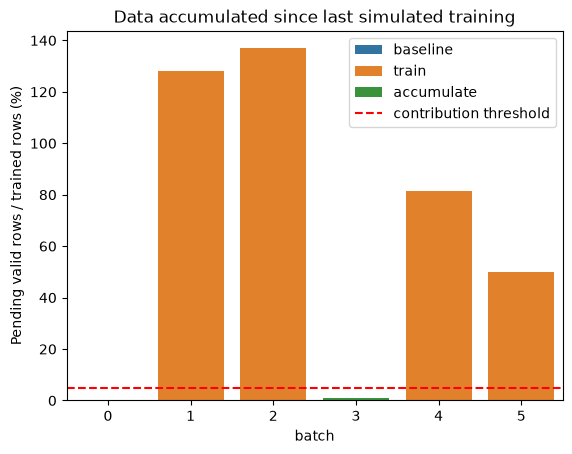

In [12]:
display(results[['batch', 'trained_rows_before', 'pending_valid_rows', 'pending_vs_trained_%', 'max_PSI', 'decision', 'reason']])
sns.barplot(data=results, x='batch', y='pending_vs_trained_%', hue='decision', dodge=False)
plt.axhline(100 * MIN_PENDING_RATIO, color='red', linestyle='--', label='contribution threshold')
plt.ylabel('Pending valid rows / trained rows (%)')
plt.title('Data accumulated since last simulated training')
plt.legend()
plt.show()
